<a href="https://colab.research.google.com/github/anupbagale/segmentation-colormap/blob/main/notebooks/02_segmentation_lookup_table.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Colouring a brain segmentation with a lookup table

FreeSurfer splits a brain MRI into anatomical structures and stores the result as a volume with one
integer label per voxel: 2 for left cerebral white matter, 17 for the left hippocampus, and so on.
Its lookup table, `FreeSurferColorLUT.txt`, gives every label a name and a colour. This notebook
reads both and draws the segmentation on top of the MRI.

The data is the "sample" subject from the MNE-Python project (CC0 licence), downsampled to
3 mm voxels so the files stay small. See `data/README.md` for details.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

In [2]:
from pathlib import Path
import urllib.request

try:
    import nibabel as nib
except ImportError:                               # not installed yet, e.g. on Colab
    %pip install -q nibabel
    import nibabel as nib

DATA_URL = "https://raw.githubusercontent.com/anupbagale/segmentation-colormap/main/data/"


def data_file(name):
    """Use the file from the repository's data folder, or download it (e.g. on Colab)."""
    for folder in (Path("../data"), Path("data")):
        if (folder / name).exists():
            return folder / name
    Path("data").mkdir(exist_ok=True)
    urllib.request.urlretrieve(DATA_URL + name, Path("data") / name)
    return Path("data") / name

## Loading the volumes

FreeSurfer stores volumes with the axes ordered left, inferior, anterior. `as_closest_canonical`
reorders them to the usual right, anterior, superior (RAS) order, so that `[:, :, k]` is an axial
slice, `[:, k, :]` a coronal slice and `[k, :, :]` a sagittal slice.

In [3]:
t1_img = nib.load(data_file("T1.mgz"))
seg_img = nib.load(data_file("aseg.mgz"))
print("original axis order:", nib.aff2axcodes(t1_img.affine))

t1 = np.asarray(nib.as_closest_canonical(t1_img).dataobj)
seg = np.asarray(nib.as_closest_canonical(seg_img).dataobj).astype(int)
print("after reordering:   ", nib.aff2axcodes(nib.as_closest_canonical(t1_img).affine))
print("shape:", t1.shape, " voxel size (mm):", t1_img.header.get_zooms())

if t1.shape != seg.shape:
    print(f"shape mismatch: {t1.shape} vs {seg.shape}")
else:
    print("MRI and segmentation have the same shape")

original axis order: ('L', 'I', 'A')
after reordering:    ('R', 'A', 'S')
shape: (86, 86, 86)  voxel size (mm): (np.float32(3.0), np.float32(3.0), np.float32(3.0))
MRI and segmentation have the same shape


## The labels

In [4]:
present = np.unique(seg)
print(len(present), "labels:", present)

46 labels: [  0   2   3   4   5   7   8  10  11  12  13  14  15  16  17  18  24  26
  28  30  31  41  42  43  44  46  47  49  50  51  52  53  54  58  60  62
  63  72  77  80  85 251 252 253 254 255]


The labels are not 0, 1, 2, ... 45. They have gaps and go up to 255. That is the main thing to
handle when colouring them.

## Reading the lookup table

Each line of the table is `label name R G B A`. Lines starting with `#` are comments. The full
FreeSurfer table has over a thousand entries; `data/aseg_lut.txt` holds just the ones used in this
segmentation, with the same names and colours.

In [5]:
lut_names = {}
lut_rgb = {}
with open(data_file("aseg_lut.txt")) as f:
    for line in f:
        if line.startswith("#") or not line.strip():
            continue
        label, name, r, g, b, _ = line.split()
        lut_names[int(label)] = name
        lut_rgb[int(label)] = np.array([int(r), int(g), int(b)]) / 255

for label in [0, 2, 3, 17, 53, 255]:
    print(f"{label:>3}  {lut_names[label]:<28} RGB {np.round(lut_rgb[label] * 255).astype(int)}")

  0  Unknown                      RGB [0 0 0]
  2  Left-Cerebral-White-Matter   RGB [245 245 245]
  3  Left-Cerebral-Cortex         RGB [205  62  78]
 17  Left-Hippocampus             RGB [220 216  20]
 53  Right-Hippocampus            RGB [220 216  20]
255  CC_Anterior                  RGB [  0   0 255]


## First approach: remap the labels

The first version of this notebook built a colour map with one colour per label in a fixed list,
then replaced every label with its position in that list (2 becomes 1, 3 becomes 2, ..., 255
becomes 44) so it could be used as an index. The list was copied by hand from the labels of one
particular scan.

This scan contains one label that the old list did not have, 72 (`5th-Ventricle`). Label 72 is
never replaced, and indexing a 45-colour array with 72 fails:

In [6]:
OLD_LABEL_LIST = np.array([0, 2, 3, 4, 5, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 24, 26, 28, 30,
                           31, 41, 42, 43, 44, 46, 47, 49, 50, 51, 52, 53, 54, 58, 60, 62, 63, 77,
                           80, 85, 251, 252, 253, 254, 255])
old_colours = np.array([lut_rgb[label] for label in OLD_LABEL_LIST])

remapped = seg.copy()
for i, label in enumerate(OLD_LABEL_LIST):
    remapped[seg == label] = i

print("labels missing from the old list:", sorted(int(x) for x in set(present) - set(OLD_LABEL_LIST)))
try:
    old_colours[remapped]
except IndexError as error:
    print("IndexError:", error)

labels missing from the old list: [72]
IndexError: index 72 is out of bounds for axis 0 with size 45


## Better approach: a 256-entry table

The labels are already whole numbers between 0 and 255, so there is no need to remap them. Make a
table with one row for every possible label and fill in the rows that are in the lookup table.
Indexing that table with the segmentation gives a colour for every voxel in one step, for any
scan:

```
colours = table[seg]
```

The table gets a fourth column for transparency (alpha). Label 0, the background, gets alpha 0 so
the MRI shows through. Labels missing from the lookup table would also stay transparent instead of
causing an error.

In [7]:
table = np.zeros((256, 4))                        # R, G, B, alpha for labels 0..255
for label, rgb in lut_rgb.items():
    table[label, :3] = rgb
    table[label, 3] = 0 if label == 0 else 1

colours = table[seg]                              # shape (86, 86, 86, 4)
print("segmentation:", seg.shape, " colour volume:", colours.shape)

segmentation: (86, 86, 86)  colour volume: (86, 86, 86, 4)


## Drawing the overlay

Images are stored with the first axis running left to right, but `imshow` puts the first axis
vertically, so each slice is transposed (`.T`) and drawn with `origin="lower"` to keep the top of
the head at the top.

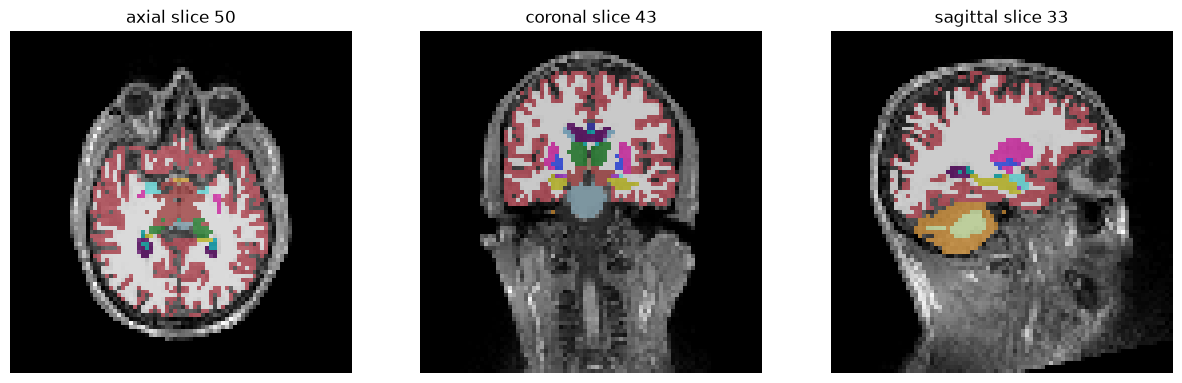

In [8]:
def show_slice(ax, axis, k, alpha=0.6):
    background = np.take(t1, k, axis=axis).T
    overlay = np.take(colours, k, axis=axis).transpose(1, 0, 2).copy()
    overlay[..., 3] *= alpha
    ax.imshow(background, cmap="gray", origin="lower")
    ax.imshow(overlay, origin="lower")
    ax.axis("off")


views = [("axial", 2, 50), ("coronal", 1, 43), ("sagittal", 0, 33)]

fig, ax = plt.subplots(1, 3, figsize=(15, 5.2))
for a, (name, axis, k) in zip(ax, views):
    show_slice(a, axis, k)
    a.set_title(f"{name} slice {k}")
plt.show()

## Which structure is which

A legend with the names from the lookup table, for the structures visible in the coronal slice.
Left and right structures share a colour, so each colour is listed once.

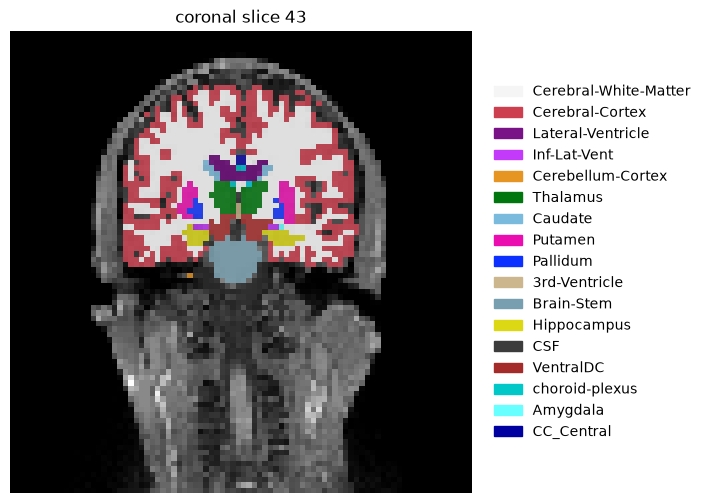

In [9]:
coronal = np.take(seg, 43, axis=1)
seen = {}
for label in np.unique(coronal):
    if label == 0:
        continue
    name = lut_names[label].replace("Left-", "").replace("Right-", "")
    seen.setdefault(name, lut_rgb[label])

fig, ax = plt.subplots(figsize=(11, 6))
show_slice(ax, 1, 43, alpha=0.8)
ax.legend(handles=[Patch(color=c, label=n) for n, c in seen.items()],
          loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
ax.set_title("coronal slice 43")
plt.show()

## Comparison with the first version

The first version overlaid the segmentation with `alpha=0.5` over the whole slice, including the
background, which is black in the lookup table. That darkened the whole MRI. Here label 0 is
transparent, so only the segmented structures are tinted.

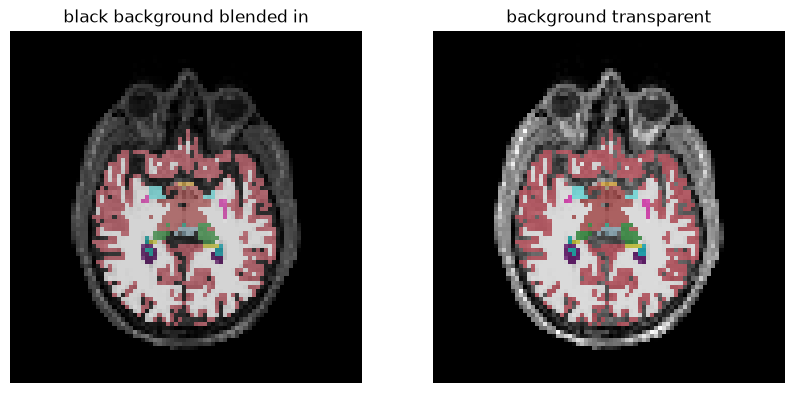

In [10]:
old_overlay = np.take(table[seg][..., :3], 50, axis=2).transpose(1, 0, 2)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(np.take(t1, 50, axis=2).T, cmap="gray", origin="lower")
ax[0].imshow(old_overlay, alpha=0.5, origin="lower")
ax[0].set_title("black background blended in")
show_slice(ax[1], 2, 50)
ax[1].set_title("background transparent")
for a in ax:
    a.axis("off")
plt.show()

## Size of each structure

The lookup table also makes it easy to put names on numbers. Counting the voxels with each label
and multiplying by the volume of one voxel gives the volume of every structure. These numbers are
rough, because at 3 mm a single voxel is 27 mm³ and small structures are only a few voxels.

In [11]:
voxel_mm3 = float(np.prod(seg_img.header.get_zooms()))
counts = np.bincount(seg.ravel(), minlength=256)

rows = [(lut_names[label], counts[label] * voxel_mm3 / 1000) for label in present if label != 0]
rows.sort(key=lambda r: r[1], reverse=True)

print(f"{'structure':<30} {'volume (cm³)':>12}")
for name, cm3 in rows[:12]:
    print(f"{name:<30} {cm3:12.1f}")

structure                      volume (cm³)
Left-Cerebral-White-Matter            282.9
Right-Cerebral-White-Matter           274.1
Right-Cerebral-Cortex                 254.6
Left-Cerebral-Cortex                  246.5
Right-Cerebellum-Cortex                52.5
Left-Cerebellum-Cortex                 50.9
Brain-Stem                             24.4
Left-Cerebellum-White-Matter           17.0
Right-Cerebellum-White-Matter          13.8
Left-Lateral-Ventricle                 11.2
Right-Thalamus                          8.7
Right-Lateral-Ventricle                 8.6
